# VECTOR HOÁ TF-IDF, CÁC MÔ HÌNH BASELINE VÀ HYPERPARAMETER TUNING

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
PROC_DIR = os.path.join(ROOT, 'data', 'processed')
MODEL_DIR = os.path.join(ROOT, 'models')
FIG_DIR = os.path.join(ROOT, 'reports', 'figures')
os.makedirs(MODEL_DIR, exist_ok=True)

In [3]:
df_train = pd.read_csv(os.path.join(PROC_DIR, 'train_clean.csv'))
df_dev = pd.read_csv(os.path.join(PROC_DIR, 'dev_clean.csv'))
df_test = pd.read_csv(os.path.join(PROC_DIR, 'test_clean.csv'))

In [4]:
for df in [df_train, df_dev, df_test]:
    df['sentence_clean'] = df['sentence_clean'].fillna('')

In [5]:
df_train.shape, df_dev.shape, df_test.shape

((11426, 10), (1583, 10), (3166, 10))

## KIỂM TRA CHỐNG RÒ RỈ DỮ LIỆU GIỮA TRAIN VÀ TEST

In [6]:
#Kiểm tra xem có câu nào bị trùng lặp giữa tập train và tập test không
overlap_test = set(df_train['sentence_clean']).intersection(set(df_test['sentence_clean']))
print('so cau trung giua train va test: ', len(overlap_test), '/', len(df_test))

so cau trung giua train va test:  1 / 3166


## TF-IDF VECTORIZATION (CHỈ FIT TRÊN TRAIN)

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

In [8]:
#Đặt min_df=3 và max_df=0.95 để bỏ các từ quá hiếm dễ gây học vẹt, chỉ fit trên TRAIN
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=12000, min_df=3, max_df=0.95, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(df_train['sentence_clean'])
X_dev_tfidf = tfidf.transform(df_dev['sentence_clean'])
X_test_tfidf = tfidf.transform(df_test['sentence_clean'])

In [9]:
X_train_tfidf.shape, X_dev_tfidf.shape, X_test_tfidf.shape

((11426, 8477), (1583, 8477), (3166, 8477))

In [10]:
y_train_sent = df_train['sentiment']
y_dev_sent = df_dev['sentiment']
y_test_sent = df_test['sentiment']

y_train_top = df_train['topic']
y_dev_top = df_dev['topic']
y_test_top = df_test['topic']

In [11]:
#Tính trọng số lớp làm mượt bằng căn bậc hai (sqrt inverse frequency) chỉ trên tập TRAIN
sent_cnt = y_train_sent.value_counts().sort_index()
smooth_w_sent = {i: float(np.sqrt(len(y_train_sent) / (3.0 * sent_cnt[i]))) for i in sent_cnt.index}

top_cnt = y_train_top.value_counts().sort_index()
smooth_w_top = {i: float(np.sqrt(len(y_train_top) / (4.0 * top_cnt[i]))) for i in top_cnt.index}
print('smooth_w_sent:', smooth_w_sent)
print('smooth_w_top:', smooth_w_top)

smooth_w_sent: {0: 0.8457201466857533, 1: 2.8837243426556975, 2: 0.8215451901739204}
smooth_w_top: {0: 0.5914423603682875, 1: 1.1392186678171732, 2: 2.3973912716652532, 3: 2.2544933385404207}


## PHẦN A — PHÂN LOẠI CẢM XÚC (SENTIMENT)

### MÔ HÌNH 1: COMPLEMENT NAIVE BAYES

In [12]:
from sklearn.naive_bayes import ComplementNB

nb_sent = ComplementNB()
nb_sent.fit(X_train_tfidf, y_train_sent)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueOnly used in edge case with a single class in the training set.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. Not used.",None
,"norm norm: bool, default=FalseWhether or not a second normalization of the weights is performed. Thedefault behavior mirrors the implementations found in Mahout and Weka,which do not follow the full algorithm described in Table 9 of thepaper.",False


In [13]:
#So sánh train vs dev trước khi tune
print('nb sent f1 train: ', f1_score(y_train_sent, nb_sent.predict(X_train_tfidf), average='macro'))
print('nb sent f1 dev:   ', f1_score(y_dev_sent, nb_sent.predict(X_dev_tfidf), average='macro'))

nb sent f1 train:  0.7340368769557019
nb sent f1 dev:    0.6729168490993586


### MÔ HÌNH 2: LOGISTIC REGRESSION

In [14]:
from sklearn.linear_model import LogisticRegression

lr_sent = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_sent.fit(X_train_tfidf, y_train_sent)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [15]:
print('lr sent f1 train: ', f1_score(y_train_sent, lr_sent.predict(X_train_tfidf), average='macro'))
print('lr sent f1 dev:   ', f1_score(y_dev_sent, lr_sent.predict(X_dev_tfidf), average='macro'))

lr sent f1 train:  0.8551520199486502
lr sent f1 dev:    0.7486936562319965


### MÔ HÌNH 3: LINEAR SVC

In [16]:
from sklearn.svm import LinearSVC

svc_sent = LinearSVC(class_weight='balanced', max_iter=3000, random_state=42)
svc_sent.fit(X_train_tfidf, y_train_sent)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseud

In [17]:
print('svc sent f1 train: ', f1_score(y_train_sent, svc_sent.predict(X_train_tfidf), average='macro'))
print('svc sent f1 dev:   ', f1_score(y_dev_sent, svc_sent.predict(X_dev_tfidf), average='macro'))

svc sent f1 train:  0.9717705823384714
svc sent f1 dev:    0.7664193893944954


### HYPERPARAMETER TUNING CHO CẢ 3 MÔ HÌNH SENTIMENT (RANDOMIZEDSEARCHCV)

In [18]:
from sklearn.model_selection import RandomizedSearchCV

#1. Tune ComplementNB (dò alpha và norm trên tập train với cv=3)
nb_params = {'alpha': [0.05, 0.1, 0.3, 0.5, 1.0, 2.0, 5.0], 'norm': [True, False]}
nb_search = RandomizedSearchCV(ComplementNB(), param_distributions=nb_params, n_iter=10, cv=3, scoring='f1_macro', random_state=42)
nb_search.fit(X_train_tfidf, y_train_sent)
nb_sent_best = nb_search.best_estimator_
print('nb best params: ', nb_search.best_params_)
print('nb tuned f1 dev: ', f1_score(y_dev_sent, nb_sent_best.predict(X_dev_tfidf), average='macro'))

nb best params:  {'norm': True, 'alpha': 0.3}
nb tuned f1 dev:  0.7137956408868048


In [19]:
#2. Tune LogisticRegression (dò C và class_weight với cv=3)
lr_params = {
    'C': [0.1, 0.2, 0.3, 0.5, 0.8, 1.0, 2.0, 5.0],
    'class_weight': [None, 'balanced', smooth_w_sent]
}
lr_search = RandomizedSearchCV(LogisticRegression(max_iter=1000, random_state=42), param_distributions=lr_params, n_iter=12, cv=3, scoring='f1_macro', random_state=42)
lr_search.fit(X_train_tfidf, y_train_sent)
lr_sent_best = lr_search.best_estimator_
print('lr best params: ', lr_search.best_params_)
print('lr tuned f1 train: ', f1_score(y_train_sent, lr_sent_best.predict(X_train_tfidf), average='macro'))
print('lr tuned f1 dev:   ', f1_score(y_dev_sent, lr_sent_best.predict(X_dev_tfidf), average='macro'))

lr best params:  {'class_weight': None, 'C': 5.0}
lr tuned f1 train:  0.9265305068925808
lr tuned f1 dev:    0.726066287587726


In [20]:
#3. Tune LinearSVC (thử 16 tổ hợp C, class_weight, loss với cv=3)
svc_params = {
    'C': [0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0, 2.0],
    'class_weight': [None, 'balanced', smooth_w_sent],
    'loss': ['hinge', 'squared_hinge']
}
svc_search = RandomizedSearchCV(LinearSVC(max_iter=3000, random_state=42), param_distributions=svc_params, n_iter=16, cv=3, scoring='f1_macro', random_state=42)
svc_search.fit(X_train_tfidf, y_train_sent)
svc_sent_best = svc_search.best_estimator_
print('svc best params: ', svc_search.best_params_)
print('svc tuned f1 train: ', f1_score(y_train_sent, svc_sent_best.predict(X_train_tfidf), average='macro'))
print('svc tuned f1 dev:   ', f1_score(y_dev_sent, svc_sent_best.predict(X_dev_tfidf), average='macro'))

svc best params:  {'loss': 'squared_hinge', 'class_weight': 'balanced', 'C': 0.5}
svc tuned f1 train:  0.954176378739818
svc tuned f1 dev:    0.7681037973943754


## PHẦN B — PHÂN LOẠI CHỦ ĐỀ (TOPIC) & HYPERPARAMETER TUNING

In [21]:
nb_top = ComplementNB()
nb_top.fit(X_train_tfidf, y_train_top)
print('nb topic f1 dev: ', f1_score(y_dev_top, nb_top.predict(X_dev_tfidf), average='macro'))

nb topic f1 dev:  0.6690671823827365


In [22]:
#Tune LogisticRegression cho bài toán Topic
lr_top_params = {
    'C': [0.1, 0.2, 0.3, 0.5, 0.8, 1.0, 2.0, 5.0],
    'class_weight': [None, 'balanced', smooth_w_top]
}
lr_top_search = RandomizedSearchCV(LogisticRegression(max_iter=1000, random_state=42), param_distributions=lr_top_params, n_iter=12, cv=3, scoring='f1_macro', random_state=42)
lr_top_search.fit(X_train_tfidf, y_train_top)
lr_top_best = lr_top_search.best_estimator_
print('lr topic best params: ', lr_top_search.best_params_)
print('lr topic tuned f1 dev: ', f1_score(y_dev_top, lr_top_best.predict(X_dev_tfidf), average='macro'))

lr topic best params:  {'class_weight': {0: 0.5914423603682875, 1: 1.1392186678171732, 2: 2.3973912716652532, 3: 2.2544933385404207}, 'C': 0.5}
lr topic tuned f1 dev:  0.7575304038601787


In [23]:
#Tune LinearSVC cho bài toán Topic
svc_top_params = {
    'C': [0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0, 2.0],
    'class_weight': [None, 'balanced', smooth_w_top],
    'loss': ['hinge', 'squared_hinge']
}
svc_top_search = RandomizedSearchCV(LinearSVC(max_iter=3000, random_state=42), param_distributions=svc_top_params, n_iter=16, cv=3, scoring='f1_macro', random_state=42)
svc_top_search.fit(X_train_tfidf, y_train_top)
svc_top_best = svc_top_search.best_estimator_
print('svc topic best params: ', svc_top_search.best_params_)
print('svc topic tuned f1 train: ', f1_score(y_train_top, svc_top_best.predict(X_train_tfidf), average='macro'))
print('svc topic tuned f1 dev:   ', f1_score(y_dev_top, svc_top_best.predict(X_dev_tfidf), average='macro'))

svc topic best params:  {'loss': 'squared_hinge', 'class_weight': 'balanced', 'C': 0.05}
svc topic tuned f1 train:  0.8461218801922339
svc topic tuned f1 dev:    0.7531489652634961


## PHẦN C — MỞ NIÊM PHONG TẬP TEST ĐÁNH GIÁ LẦN CUỐI

In [24]:
pred_sent_test = svc_sent_best.predict(X_test_tfidf)
pred_top_test = svc_top_best.predict(X_test_tfidf)

print('=== KET QUA CUOI CUNG TREN TAP TEST (3,166 CAU) ===')
print('sentiment macro f1 test: ', f1_score(y_test_sent, pred_sent_test, average='macro'))
print('sentiment acc test:      ', accuracy_score(y_test_sent, pred_sent_test))
print('topic macro f1 test:     ', f1_score(y_test_top, pred_top_test, average='macro'))
print('topic acc test:          ', accuracy_score(y_test_top, pred_top_test))

=== KET QUA CUOI CUNG TREN TAP TEST (3,166 CAU) ===
sentiment macro f1 test:  0.7379752868621482
sentiment acc test:       0.8913455464308275
topic macro f1 test:      0.7446992087951502
topic acc test:           0.8474415666456097


In [25]:
print(classification_report(y_test_sent, pred_sent_test, target_names=['negative', 'neutral', 'positive']))
print(classification_report(y_test_top, pred_top_test, target_names=['lecturer', 'training_program', 'facility', 'others']))

              precision    recall  f1-score   support

    negative       0.88      0.95      0.91      1409
     neutral       0.46      0.33      0.38       167
    positive       0.94      0.90      0.92      1590

    accuracy                           0.89      3166
   macro avg       0.76      0.73      0.74      3166
weighted avg       0.89      0.89      0.89      3166

                  precision    recall  f1-score   support

        lecturer       0.94      0.89      0.91      2290
training_program       0.65      0.77      0.70       572
        facility       0.90      0.91      0.91       145
          others       0.45      0.47      0.46       159

        accuracy                           0.85      3166
       macro avg       0.73      0.76      0.74      3166
    weighted avg       0.86      0.85      0.85      3166



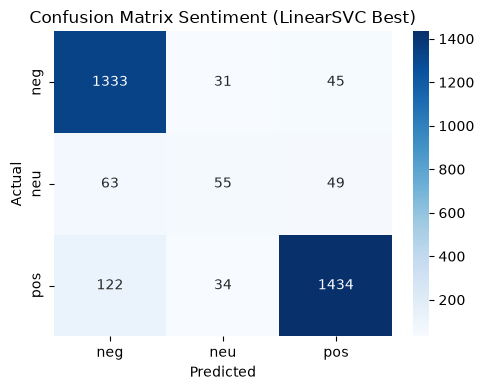

In [26]:
cm_sent = confusion_matrix(y_test_sent, pred_sent_test)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_sent, annot=True, fmt='d', cmap='Blues', xticklabels=['neg', 'neu', 'pos'], yticklabels=['neg', 'neu', 'pos'])
plt.title('Confusion Matrix Sentiment (LinearSVC Best)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'cm_baseline_sentiment.png'), dpi=150)
plt.show()

In [27]:
#Lưu vectorizer và các model đã tune tốt nhất
joblib.dump(tfidf, os.path.join(MODEL_DIR, 'tfidf_vectorizer.pkl'))
joblib.dump(lr_sent_best, os.path.join(MODEL_DIR, 'lr_sentiment.pkl'))
joblib.dump(lr_top_best, os.path.join(MODEL_DIR, 'lr_topic.pkl'))
joblib.dump(svc_sent_best, os.path.join(MODEL_DIR, 'svc_sentiment.pkl'))
joblib.dump(svc_top_best, os.path.join(MODEL_DIR, 'svc_topic.pkl'))

['d:\\VSFC-Feedback-Analyzer\\models\\svc_topic.pkl']

In [28]:
df_out = df_test.copy()
df_out['pred_sentiment_baseline'] = pred_sent_test
df_out['pred_topic_baseline'] = pred_top_test
df_out['prob_sentiment_baseline'] = lr_sent_best.predict_proba(X_test_tfidf).max(axis=1).round(4)
df_out['prob_topic_baseline'] = lr_top_best.predict_proba(X_test_tfidf).max(axis=1).round(4)
df_out.to_csv(os.path.join(PROC_DIR, 'test_pred_baseline.csv'), index=False, encoding='utf-8-sig')